# 02 — Feature Engineering

**Goal:** add baseball-informed features to the cleaned data.

Background: a team's winning % is mostly set by runs scored vs allowed (Bill James' **Pythagorean expectation**), which typically misses by ~4 wins per season. Most of that leftover is how a team does in close games, so we also add features that capture close-game results.

| Group | Features | Why |
|---|---|---|
| Run-based | `pythpat_W`, `pyth_W`, `RD`, `RD_pg`, `log_R_RA`, `R_pg`, `RA_pg` | runs scored vs allowed drive wins |
| Close-game | `SV_pg`, `SHO_pg`, `CG_pg`, `IP_pg` | explain what Pythagorean expectation misses |
| Era-relative | `R_rel`, `RA_rel` | scoring relative to the season's league average |
| Offense rates | `OBP`, `SLG`, `OPS`, `ISO`, `RC_pg` | standard batting quality measures |
| Pitching/defense rates | `WHIP`, `K9`, `BB9`, `HR9`, `FIP_core`, `UER`, `E_pg` | standard run-prevention measures |

Steps:
1. Load cleaned data
2. Define and apply `add_features`, with a feature dictionary explaining each one in baseball terms
3. Sanity checks
4. Explore the new features
5. Redundancy
6. Evaluate: do they help?
7. Save

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, GroupKFold, cross_val_score

sns.set_theme(style='whitegrid')

# works whether the kernel starts in notebooks/, Model-3-Project/ or DSAI/
DATA_DIR = next(p for p in [Path('../Data'), Path('Data'), Path('Model-3-Project/Data')]
                if (p / 'train_clean.csv').exists())
ARTIFACT_DIR = DATA_DIR.parent / 'artifacts'
ARTIFACT_DIR.mkdir(exist_ok=True)

train = pd.read_csv(DATA_DIR / 'train_clean.csv')
pred = pd.read_csv(DATA_DIR / 'predict_clean.csv')
print('train:', train.shape, '| predict:', pred.shape)

train: (1412, 50) | predict: (400, 48)


## 1. Define the features
Everything is computed row by row from that team-season's own stats, so the same function applies to `predict.csv` with no information from other rows (no leakage).

Notes on formulas:
- **Pythagenpat** sets the exponent from the scoring environment: x = ((R + RA) / G)^0.287. That matters across eras where runs per game ranged from ~3.4 to ~5.5.
- `OBP` is approximate (`(H + BB) / (AB + BB)`): the data has no hit-by-pitch or sacrifice-fly columns.
- `FIP_core` is fielding-independent pitching **without the yearly constant**, which only shifts the value and doesn't matter to a model.
- Per-game rates (`_pg`) remove the effect of season length (`G` ranges 150–165).

In [2]:
FEATURE_GROUPS = {
    'run_based':     ['pythpat_W', 'pyth_W', 'RD', 'RD_pg', 'log_R_RA', 'R_pg', 'RA_pg'],
    'close_game':    ['SV_pg', 'SHO_pg', 'CG_pg', 'IP_pg'],
    'era_relative':  ['R_rel', 'RA_rel'],
    'offense':       ['OBP', 'SLG', 'OPS', 'ISO', 'RC_pg'],
    'pitch_defense': ['WHIP', 'K9', 'BB9', 'HR9', 'FIP_core', 'UER', 'E_pg'],
}
ENGINEERED = [f for group in FEATURE_GROUPS.values() for f in group]


def add_features(df):
    d = df.copy()
    G = d['G']
    IP = d['IPouts'] / 3                       # innings pitched
    TB = d['H'] + d['2B'] + 2 * d['3B'] + 3 * d['HR']   # total bases

    # run-based
    d['RD'] = d['R'] - d['RA']
    d['RD_pg'] = d['RD'] / G
    d['R_pg'] = d['R'] / G
    d['RA_pg'] = d['RA'] / G
    d['log_R_RA'] = np.log(d['R'] / d['RA'])
    d['pyth_W'] = G * d['R']**1.83 / (d['R']**1.83 + d['RA']**1.83)
    x = ((d['R'] + d['RA']) / G) ** 0.287
    d['pythpat_W'] = G * d['R']**x / (d['R']**x + d['RA']**x)

    # close-game
    d['SV_pg'] = d['SV'] / G                   # a save requires a close win
    d['SHO_pg'] = d['SHO'] / G                 # every shutout is a win
    d['CG_pg'] = d['CG'] / G
    d['IP_pg'] = d['IPouts'] / G               # winning home teams skip the bottom of the 9th

    # era-relative
    d['R_rel'] = d['R_pg'] / d['mlb_rpg']
    d['RA_rel'] = d['RA_pg'] / d['mlb_rpg']

    # offense
    d['OBP'] = (d['H'] + d['BB']) / (d['AB'] + d['BB'])
    d['SLG'] = TB / d['AB']
    d['OPS'] = d['OBP'] + d['SLG']
    d['ISO'] = d['SLG'] - d['H'] / d['AB']
    d['RC_pg'] = (d['H'] + d['BB']) * TB / (d['AB'] + d['BB']) / G   # Bill James runs created

    # pitching / defense
    d['WHIP'] = (d['HA'] + d['BBA']) / IP
    d['K9'] = 9 * d['SOA'] / IP
    d['BB9'] = 9 * d['BBA'] / IP
    d['HR9'] = 9 * d['HRA'] / IP
    d['FIP_core'] = (13 * d['HRA'] + 3 * d['BBA'] - 2 * d['SOA']) / IP
    d['UER'] = d['RA'] - d['ER']               # unearned runs (caused by errors)
    d['E_pg'] = d['E'] / G

    assert set(ENGINEERED) <= set(d.columns)
    return d


train_fe = add_features(train)
pred_fe = add_features(pred)
print(f'Added {len(ENGINEERED)} features | train: {train_fe.shape} | predict: {pred_fe.shape}')

Added 25 features | train: (1412, 75) | predict: (400, 73)


### Feature dictionary

For every engineered feature, this section gives:
- **Calculation**: the formula used in `add_features`.
- **Why these terms**: the baseball reasoning for combining the stats this way.
- **In real life**: what the number means on the field, using the **1998 New York Yankees** (114–48, one of the best teams ever) as a worked example. "Median" means the median team-season in the training data.

**Two building blocks** appear in several formulas:

| Symbol | Calculation | Baseball meaning |
|---|---|---|
| `IP` | `IPouts / 3` | Innings pitched. An inning is 3 outs, so outs ÷ 3 = innings. |
| `TB` | `H + 2B + 2·3B + 3·HR` | Total bases. A single is worth 1 base, a double 2, a triple 3, a home run 4. `H` already counts every hit once, so a double needs 1 extra base, a triple 2 extra and a home run 3 extra. |

**Why so many features are "per game" (`_pg`):** seasons in this data run from 150 to 165 games. Dividing by `G` asks "how good was this team *each day*?" rather than "how much did it pile up?", so a 154-game season from 1950 and a 162-game season from 2010 are on the same scale.

---

#### 1. Run-based features: *you win by outscoring the other team*

Every game is decided by one comparison: runs scored vs runs allowed. Over a season, the gap between `R` and `RA` is the strongest clue to how many games a team won. These features express that gap in different shapes.

**`RD`: run differential**
- **Calculation:** `R − RA`
- **Why these terms:** a win is simply scoring more than the opponent, so subtracting runs allowed from runs scored gives the season-long "scoreboard margin". Offense adds to it, pitching and defense subtract from it.
- **In real life:** the rule of thumb is **about 10 runs of differential = 1 extra win** above .500 (81 wins in a 162-game season). The '98 Yankees were +309, which predicts about 81 + 31 = **112 wins**. They won 114.

**`RD_pg`: run differential per game**
- **Calculation:** `(R − RA) / G`
- **Why these terms:** same margin, divided by games so seasons of different lengths compare fairly.
- **In real life:** the average margin of victory (or defeat) per game. The '98 Yankees outscored opponents by **+1.9 runs every game**. The median team is about 0.

**`R_pg` and `RA_pg`: runs scored and allowed per game**
- **Calculation:** `R / G` and `RA / G`
- **Why these terms:** splitting the differential back into its two halves lets the model weigh offense and run prevention separately. A team can reach +1 per game by scoring 6 and allowing 5, or scoring 4 and allowing 3, and those aren't quite the same (see Pythagenpat below).
- **In real life:** the '98 Yankees scored **5.96** and allowed **4.05** runs per game. The median team scores about 4.4.

**`log_R_RA`: log run ratio**
- **Calculation:** `ln(R / RA)`
- **Why these terms:** winning depends on scoring *relative* to what you allow, not on the raw gap. Beating opponents 6–5 on average is closer to a coin flip than beating them 2–1, even though both margins are 1 run. The ratio `R / RA` captures this. Taking the log makes it symmetric: scoring 20% more than you allow and allowing 20% more than you score give values of the same size with opposite signs, and a perfectly even team scores exactly 0.
- **In real life:** the '98 Yankees' value of 0.386 means they scored e^0.386 = **1.47 times** as many runs as they allowed (965 vs 656).

**`pyth_W`: Pythagorean expected wins**
- **Calculation:** `G × R^1.83 / (R^1.83 + RA^1.83)`
- **Why these terms:** Bill James noticed that a team's winning percentage is close to `R² / (R² + RA²)`. It looks like the Pythagorean theorem, which gave it its name. The idea is a "share of the runs" formula: if you scored all the runs you'd win every game; if you scored as many as you allowed you'd win half. The exponent (later refined to 1.83) captures diminishing returns: once you're far ahead of opponents, each extra run converts into fewer extra wins, because you were already winning those games. Multiplying by `G` turns the percentage into a win count.
- **In real life:** "how many games *should* this team have won, given how many runs it scored and allowed?" The '98 Yankees' runs predict **108.5 wins**; they actually won 114, so they were about 5–6 wins better than their runs. Across all teams this formula misses by about 4 wins on average.

**`pythpat_W`: Pythagenpat expected wins**
- **Calculation:** `G × R^x / (R^x + RA^x)`, where `x = ((R + RA) / G)^0.287`
- **Why these terms:** the same "share of runs" idea, but the exponent changes with how many runs are scored in this team's games (`(R + RA) / G` = total runs per game, both teams combined). In a low-scoring era such as the 1960s, a single run is a bigger share of a typical game, so each run swings more wins. In a high-scoring era, games are more often decided by several runs and one run matters less. This dataset covers the dead-ball era through the steroid era (league scoring of about 3.4 to 5.5 runs per game), so a fixed exponent is wrong for some eras.
- **In real life:** the '98 Yankees' games averaged 10.0 total runs, which gives an exponent of 1.94 and an estimate of **109.9 wins**. This is the single best predictor in the data.

---

#### 2. Close-game features: *what the run totals miss*

Pythagorean expectation assumes runs are spread evenly across games. In reality, a team can win lots of one-run games, or lose 12–2 a few times and inflate `RA` without losing extra games. The wins that Pythagorean expectation misses come mostly from **close games**. These features count events that only happen in close games or in wins.

**`SV_pg`: saves per game**
- **Calculation:** `SV / G`
- **Why these terms:** a save is credited to the relief pitcher who finishes a **win** while protecting a small lead (typically 3 runs or fewer when entering). So every save is, by definition, a close win. Saves per game is close to "share of games that were close wins".
- **In real life:** the '98 Yankees saved **0.30** of their games (48 saves, mostly by Mariano Rivera); the median team saves about 0.19. A team with a strong closer turns more one-run leads into wins, which is exactly where it beats its Pythagorean estimate. This is the best single explanation of the wins Pythagorean expectation misses. (Saves became official in 1969; earlier totals were reconstructed and are lower, which the era flags handle.)

**`SHO_pg`: shutouts per game**
- **Calculation:** `SHO / G`
- **Why these terms:** if the opponent scores 0, you can't lose (a 0–0 game isn't finished). So every shutout is a guaranteed win, and the rate counts games the pitching staff won on its own.
- **In real life:** the '98 Yankees shut out opponents in **1 of every 10 games** (16 shutouts). It tracks dominant pitching, though much of that is already in a low `RA_pg`.

**`CG_pg`: complete games per game**
- **Calculation:** `CG / G`
- **Why these terms:** a complete game means the starting pitcher threw the whole game. Managers leave a starter in only when he is pitching well, and usually when the team is winning, so within an era it signals quality starting pitching.
- **In real life:** this one is also a strong **era marker**. Early-1900s starters finished about 3 in 4 of their games; by the 2010s it was about 2 in 100, because bullpens took over late innings. The '98 Yankees completed 22 games (0.14 per game), a high number for the late 1990s.

**`IP_pg`: pitching outs per game**
- **Calculation:** `IPouts / G`
- **Why these terms:** a 9-inning game is 27 outs for each pitching staff, except when the home team is already ahead after the top of the 9th. Then the game ends without the bottom of the 9th, and the **losing road team's pitchers record only 24 outs**. Walk-off wins also end the game before the losing pitchers finish the inning. In both cases it's the losing staff that records fewer outs, so winners average slightly more outs per game.
- **In real life:** a quirk of the rules turned into a win signal. The '98 Yankees recorded **26.97 outs per game**; the median team records 26.80. The gap is small, but it's consistent, and it helps explain wins beyond the run totals.

---

#### 3. Era-relative features: *good compared to whom?*

**`R_rel` and `RA_rel`: runs scored and allowed relative to the league**
- **Calculation:** `(R / G) / mlb_rpg` and `(RA / G) / mlb_rpg`, where `mlb_rpg` is the league-wide average runs per game that season
- **Why these terms:** a team only has to beat the other teams **in the same season**. Scoring 4.5 runs per game was excellent in 1968 ("the year of the pitcher") and only average in 2000. Dividing by the league average converts "how many runs" into "how much better or worse than everyone you played against". 1.00 is exactly league average.
- **In real life:** the '98 Yankees scored **24% more** runs than the average team that year (`R_rel` = 1.24) and allowed **15% fewer** (`RA_rel` = 0.85). Both features correlate more strongly with wins than the raw per-game rates, because they remove the era.

---

#### 4. Offense rates: *how a lineup produces runs*

Runs scored depend on two things: **getting runners on base** and **moving them around to score**. Each feature below measures one or both.

**`OBP`: on-base percentage**
- **Calculation:** `(H + BB) / (AB + BB)`
- **Why these terms:** the top counts every time a batter reached base safely (hit or walk); the bottom counts every chance he had (at-bats plus walks, which aren't counted as at-bats). A team gets only 27 outs per game, so OBP is effectively "how often did we *not* use up an out?". This was the central stat in *Moneyball*. (The official formula also includes hit-by-pitches and sacrifice flies, which this data doesn't have.)
- **In real life:** the '98 Yankees reached base **36.2%** of the time; the median team reaches base 32.5%. That's about 1 extra baserunner every 27 plate appearances, or roughly 1.5 extra runners per game.

**`SLG`: slugging percentage**
- **Calculation:** `TB / AB`
- **Why these terms:** total bases rewards each hit for how far it moves the batter (a home run counts 4 times as much as a single). Dividing by at-bats gives power per opportunity. Walks are excluded because they never advance a runner more than one base.
- **In real life:** average bases per at-bat. The '98 Yankees averaged **0.460 bases** per at-bat (median .390). Extra-base hits clear the bases, so a high SLG scores runs without needing three or four hits in a row.

**`OPS`: on-base plus slugging**
- **Calculation:** `OBP + SLG`
- **Why these terms:** adding the two combines "getting on" and "moving runners over" into one number. It's not mathematically pure (the denominators differ), but it tracks runs scored better than either part alone.
- **In real life:** the most common quick summary of a hitter or a lineup. An OPS above .800 is a strong offense; the '98 Yankees were at **.822**.

**`ISO`: isolated power**
- **Calculation:** `SLG − H / AB` (slugging minus batting average)
- **Why these terms:** batting average counts every hit as 1. Slugging counts it as 1 to 4. Subtracting one from the other leaves only the **extra** bases from doubles, triples and home runs. That separates raw power from contact hitting.
- **In real life:** two teams can both hit .270, but one hits singles and the other hits home runs. The '98 Yankees had **.172** extra bases per at-bat (median .128). This went up sharply in the live-ball and steroid eras.

**`RC_pg`: runs created per game**
- **Calculation:** `(H + BB) × TB / (AB + BB) / G`
- **Why these terms:** Bill James's runs-created formula is built as **(runners on base) × (how far they advance) / (opportunities)**. `H + BB` is the number of runners, `TB` is how far the hits moved everyone, and `AB + BB` is the number of plate appearances. Multiplying the two captures an important fact: getting on base and hitting for power are worth more together than apart. A home run with two men on scores 3 runs; the same home run with the bases empty scores 1.
- **In real life:** "how many runs per game *should* this lineup have scored, given its hits and walks?". The '98 Yankees' hitting predicts **5.80** runs per game, and they actually scored 5.96. A team that beats its runs-created figure scored more than its hitting suggests, through clutch hitting, baserunning or luck.

---

#### 5. Pitching and defense rates: *how a team prevents runs*

These mirror the offense rates from the other side of the ball. Pitching stats are scaled per inning (`IP`) or per 9 innings (one full game) so staffs that pitched different numbers of innings compare fairly.

**`WHIP`: walks plus hits per inning pitched**
- **Calculation:** `(HA + BBA) / IP`
- **Why these terms:** hits and walks allowed are the two main ways opponents reach base. Adding them counts the baserunners a staff gave up, and dividing by innings turns that into a rate. It's the pitching mirror of OBP.
- **In real life:** "how many runners does the opponent get each inning?". The '98 Yankees allowed **1.25** per inning, about 11 per game; the median staff allows 1.36. Fewer runners means fewer chances to score. This is the strongest win predictor in the pitching group.

**`K9`: strikeouts per 9 innings**
- **Calculation:** `9 × SOA / IP`
- **Why these terms:** a strikeout is an out with no ball in play, so there's no chance of a hit, an error or a runner advancing. Multiplying the per-inning rate by 9 expresses it per full game.
- **In real life:** the '98 Yankees struck out **6.7** batters per game. Strikeouts rose steadily over the century (median 5.3 here), so this matters most when compared within an era.

**`BB9`: walks per 9 innings**
- **Calculation:** `9 × BBA / IP`
- **Why these terms:** a walk is a free baserunner the pitcher gave away without the batter doing anything. It measures a staff's control.
- **In real life:** the '98 Yankees walked **2.9** batters per game (median 3.2). Walks that are followed by a hit or home run are how many big innings start.

**`HR9`: home runs allowed per 9 innings**
- **Calculation:** `9 × HRA / IP`
- **Why these terms:** a home run is the most damaging single event in baseball: it scores at least one run immediately and clears any runners on base. No fielder can stop it.
- **In real life:** the '98 Yankees allowed **0.96** home runs per game. Like strikeouts, home runs rose sharply over time (the median team went from about 0.1 per game in the 1900s to about 1.0 in the 2000s), so this is largely an era signal unless compared within a season.

**`FIP_core`: fielding-independent pitching**
- **Calculation:** `(13 × HRA + 3 × BBA − 2 × SOA) / IP`
- **Why these terms:** strikeouts, walks and home runs are the only outcomes that involve **just the pitcher and batter**. Fielders play no part. Tom Tango's FIP weights each by its average run value compared with a ball in play, then scales to 9 innings. A home run costs about 1.4 runs (× 9 ≈ 13), a walk about 0.33 runs (× 9 ≈ 3), and a strikeout saves about 0.22 runs (× 9 ≈ 2, which is why it's subtracted). The official FIP adds a yearly constant (about 3.1) to put it on the ERA scale. That constant only shifts every value equally, so it's left out here.
- **In real life:** "how many runs did the pitchers *deserve* to allow, ignoring their fielders and luck on balls in play?". Lower is better. The '98 Yankees scored **0.87** (about 4.0 on the ERA scale once the constant is added); the median is 1.03.

**`UER`: unearned runs**
- **Calculation:** `RA − ER`
- **Why these terms:** official scorers mark a run as "earned" only if it would have scored without any fielding errors or passed balls. All runs minus earned runs leaves the runs that were the defense's fault, not the pitcher's.
- **In real life:** runs given away by poor fielding. The '98 Yankees allowed only **38** unearned runs all season; the median team allowed 78. The median team in the 1900s gave away about 160, and the worst over 250.

**`E_pg`: errors per game**
- **Calculation:** `E / G`
- **Why these terms:** an error gives the opponent an extra baserunner or an extra base, and often an extra out to work with in the inning. Per game removes season length.
- **In real life:** the '98 Yankees made **0.60** errors per game; the median team makes 0.85. Errors fell sharply over the century as gloves and field conditions improved, so this is also an era marker. Within an era, sloppy fielding teams also lose more games than their runs suggest.

In [3]:
# every engineered feature for the 1998 Yankees next to the median team-season
example = train_fe[(train_fe['yearID'] == 1998) & (train_fe['teamID'] == 'NYA')].iloc[0]
pd.DataFrame({
    'group': pd.Series({f: g for g, fs in FEATURE_GROUPS.items() for f in fs}),
    '1998 NYA': example[ENGINEERED].astype(float),
    'league median': train_fe[ENGINEERED].median(),
}).round(3)

,group,1998 NYA,league median
pythpat_W,run_based,109.940,80.187
pyth_W,run_based,108.473,80.180
RD,run_based,309.000,3.000
RD_pg,run_based,1.907,0.019
log_R_RA,run_based,0.386,0.004
R_pg,run_based,5.957,4.390
RA_pg,run_based,4.049,4.358
SV_pg,close_game,0.296,0.187
SHO_pg,close_game,0.099,0.062
CG_pg,close_game,0.136,0.232


## 2. Sanity checks

In [4]:
for name, df in [('train', train_fe), ('predict', pred_fe)]:
    vals = df[ENGINEERED]
    assert not vals.isna().any().any(), f'{name}: NaN in engineered features'
    assert np.isfinite(vals.to_numpy()).all(), f'{name}: inf in engineered features'
print('No NaN or inf values')

train_fe[ENGINEERED].describe().T[['mean', 'std', 'min', 'max']].round(3)

No NaN or inf values


,mean,std,min,max
pythpat_W,79.538,12.702,39.688,113.245
pyth_W,79.538,12.495,38.641,111.502
RD,-0.052,121.166,-349.000,411.000
RD_pg,-0.000,0.769,-2.266,2.704
log_R_RA,-0.000,0.175,-0.583,0.553
R_pg,4.400,0.647,2.409,6.884
RA_pg,4.401,0.646,2.516,7.686
SV_pg,0.177,0.087,0.000,0.390
SHO_pg,0.065,0.030,0.000,0.206
CG_pg,0.259,0.205,0.000,0.916


The ranges look like real baseball: OBP ~0.27–0.37, SLG ~0.3–0.5, WHIP ~1.1–1.6, runs per game ~2.5–7. Next, the Pythagorean estimates against actual wins:

In [5]:
for col in ['pyth_W', 'pythpat_W']:
    err = train_fe[col] - train_fe['W']
    print(f'{col:10} RMSE vs actual W: {np.sqrt((err**2).mean()):.3f} wins | mean error: {err.mean():+.3f}')

pyth_W     RMSE vs actual W: 4.044 wins | mean error: +0.307
pythpat_W  RMSE vs actual W: 4.002 wins | mean error: +0.307


Both miss by about 4 wins, the usual figure for Pythagorean expectation. Pythagenpat is slightly better.

## 3. Explore the new features

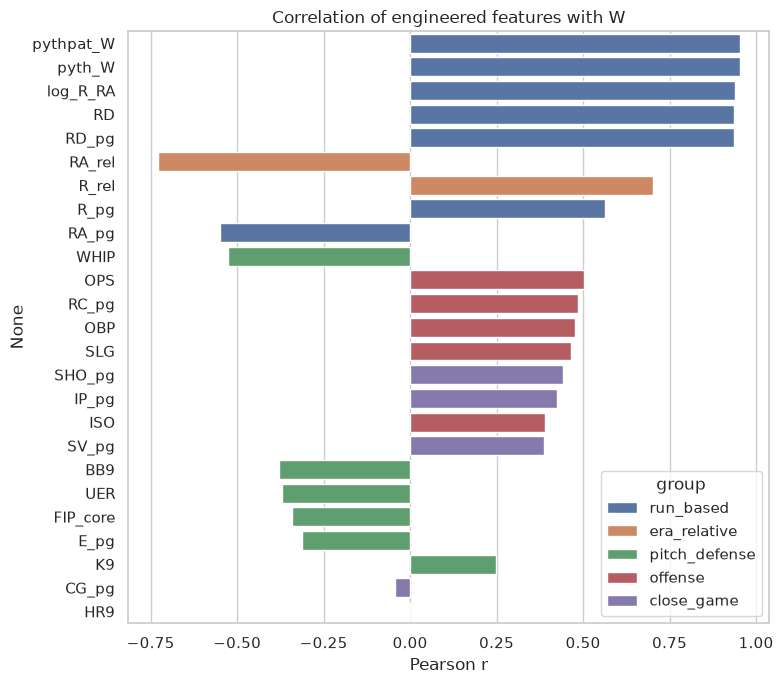

In [6]:
corr_W = train_fe[ENGINEERED].corrwith(train_fe['W']).sort_values(key=abs, ascending=False)
group_of = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}

fig, ax = plt.subplots(figsize=(8, 7))
sns.barplot(x=corr_W.values, y=corr_W.index, hue=corr_W.index.map(group_of), dodge=False, ax=ax)
ax.set_title('Correlation of engineered features with W'); ax.set_xlabel('Pearson r')
ax.legend(title='group', loc='lower right')
plt.tight_layout()

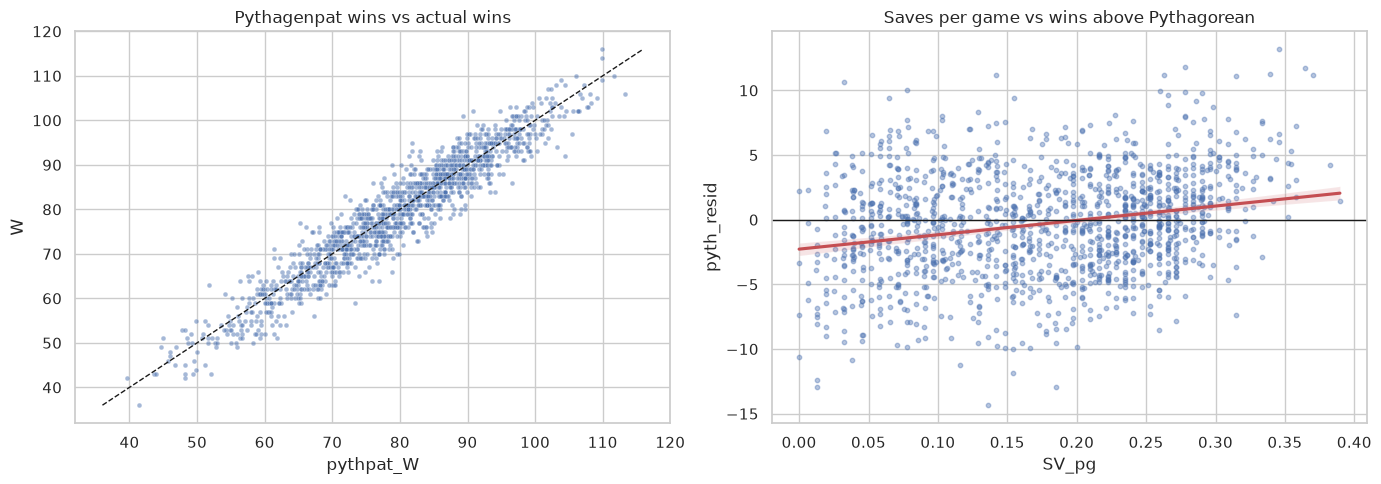

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=train_fe, x='pythpat_W', y='W', s=12, alpha=0.5, ax=axes[0])
lims = [train_fe['W'].min(), train_fe['W'].max()]
axes[0].plot(lims, lims, 'k--', lw=1); axes[0].set_title('Pythagenpat wins vs actual wins')

train_fe['pyth_resid'] = train_fe['W'] - train_fe['pythpat_W']
sns.regplot(data=train_fe, x='SV_pg', y='pyth_resid', scatter_kws={'s': 10, 'alpha': 0.4},
            line_kws={'color': 'C3'}, ax=axes[1])
axes[1].axhline(0, color='k', lw=1); axes[1].set_title('Saves per game vs wins above Pythagorean')
plt.tight_layout()

### What Pythagorean expectation misses
The leftover error (`W − pythpat_W`) is mostly close-game luck. Which features relate to it?

In [8]:
raw_numeric = [c for c in train.columns if c not in ['W', 'ID', 'yearID', 'teamID', 'decade_label']
               and not c.startswith(('era_', 'decade_'))]
resid_corr = (train_fe[ENGINEERED + raw_numeric].drop(columns=['pythpat_W', 'pyth_W'])
              .corrwith(train_fe['pyth_resid']).sort_values(key=abs, ascending=False))
resid_corr.head(10).round(3).to_frame('corr with W − pythpat_W')

,corr with W − pythpat_W
SV_pg,0.241
SV,0.237
IP_pg,0.131
CG,-0.113
CG_pg,-0.112
FP,0.112
E,-0.111
E_pg,-0.109
IPouts,0.102
SLG,0.101


`SV` / `SV_pg` lead clearly: a save only happens in a win by 3 runs or fewer, so it directly counts close wins. `IP_pg` comes next: teams that win at home often skip the bottom of the 9th, so their pitchers record a bit more of the game's outs.

In [9]:
train_fe = train_fe.drop(columns='pyth_resid')

## 4. Redundancy
Some new features are **exact** linear combinations of others. That's fine for Ridge and trees but breaks plain OLS (perfect collinearity), so we record them for the processing notebook to drop for OLS.

In [10]:
# feature -> the same value rebuilt as a linear combination of other columns
EXACT_COMBOS = {
    'RD':       lambda d: d['R'] - d['RA'],
    'RD_pg':    lambda d: d['R_pg'] - d['RA_pg'],
    'UER':      lambda d: d['RA'] - d['ER'],
    'OPS':      lambda d: d['OBP'] + d['SLG'],
    'FIP_core': lambda d: (13 * d['HR9'] + 3 * d['BB9'] - 2 * d['K9']) / 9,
}
for f, rebuild in EXACT_COMBOS.items():
    assert np.allclose(train_fe[f], rebuild(train_fe)), f
print('Exact linear combinations (drop for OLS):', list(EXACT_COMBOS))

Exact linear combinations (drop for OLS): ['RD', 'RD_pg', 'UER', 'OPS', 'FIP_core']


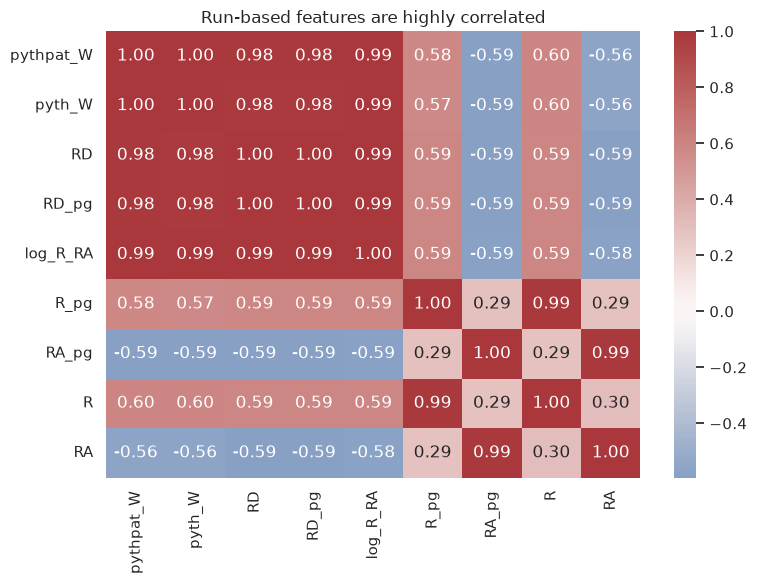

In [11]:
run_cols = FEATURE_GROUPS['run_based'] + ['R', 'RA']
plt.figure(figsize=(8, 6))
sns.heatmap(train_fe[run_cols].corr(), annot=True, fmt='.2f', cmap='vlag', center=0)
plt.title('Run-based features are highly correlated')
plt.tight_layout()

The run-based features are near-duplicates of each other (|r| ≈ 0.9–1.0). Ridge spreads weight across them, so keeping them all is fine. For OLS, or to read coefficients, keep one per group (e.g. `pythpat_W`).

## 5. Evaluate: do the features help?
Two cross-validation schemes:
- **Random 5-fold**: standard.
- **Leave one decade out**: train on all other decades, test on the held-out one. This matches the competition's goal of models that work across eras.

In [12]:
TARGET = 'W'
FLAG_COLS = [c for c in train if c.startswith(('era_', 'decade_')) and c != 'decade_label']
RAW_FEATURES = raw_numeric + FLAG_COLS
ALL_FEATURES = RAW_FEATURES + ENGINEERED

schemes = {
    'random 5-fold': (KFold(n_splits=5, shuffle=True, random_state=42), None),
    'leave-decade-out': (GroupKFold(n_splits=train['decade_label'].nunique()), train['decade_label']),
}
models = {
    'Ridge': lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50))),
    'GradientBoosting': lambda: HistGradientBoostingRegressor(random_state=42),
}
feature_sets = {
    'raw': RAW_FEATURES,
    'raw + engineered': ALL_FEATURES,
    'pythpat_W + close-game + flags': ['pythpat_W', 'G'] + FEATURE_GROUPS['close_game'] + FLAG_COLS,
}

rows = []
for model_name, make_model in models.items():
    for fs_name, cols in feature_sets.items():
        row = {'model': model_name, 'features': fs_name, 'n': len(cols)}
        for scheme, (cv, groups) in schemes.items():
            s = -cross_val_score(make_model(), train_fe[cols], train_fe[TARGET], cv=cv, groups=groups,
                                 scoring='neg_root_mean_squared_error')
            row[scheme] = round(s.mean(), 3)
        rows.append(row)
results = pd.DataFrame(rows)
results

,model,features,n,random 5-fold,leave-decade-out
0,Ridge,raw,45,3.485,3.853
1,Ridge,raw + engineered,70,3.413,3.709
2,Ridge,pythpat_W + close-game + flags,26,3.600,3.816
3,GradientBoosting,raw,45,4.117,4.438
4,GradientBoosting,raw + engineered,70,3.881,4.063
5,GradientBoosting,pythpat_W + close-game + flags,26,3.902,4.017


CV RMSE is in wins (lower is better).
- **Ridge** improves modestly: it could already combine raw `R` and `RA` linearly.
- **Gradient boosting** improves a lot: trees can't easily compute ratios like R/RA, so handing them `pythpat_W` and per-game rates helps.
- The compact `pythpat_W + close-game` set matches the full set for gradient boosting and is within ~0.2 wins for Ridge, with about a third of the features. Most of the signal is runs plus close-game results.
- Leave-decade-out errors are higher (a harder test), but the engineered features help there too.

## 6. Save

In [13]:
assert list(train_fe.columns[:len(train.columns)]) == list(train.columns)
train_fe.to_csv(DATA_DIR / 'train_features.csv', index=False)
pred_fe.to_csv(DATA_DIR / 'predict_features.csv', index=False)

fe_config = {'feature_groups': FEATURE_GROUPS, 'engineered': ENGINEERED, 'exact_combos': list(EXACT_COMBOS)}
(ARTIFACT_DIR / 'engineered_features.json').write_text(json.dumps(fe_config, indent=2))

print('Saved:', DATA_DIR / 'train_features.csv', train_fe.shape, '|', DATA_DIR / 'predict_features.csv', pred_fe.shape)
print('Saved:', ARTIFACT_DIR / 'engineered_features.json')

Saved: ../Data/train_features.csv (1412, 75) | ../Data/predict_features.csv (400, 73)
Saved: ../artifacts/engineered_features.json


## Summary
| Item | Detail |
|---|---|
| New features | 25 across 5 groups (run-based, close-game, era-relative, offense, pitching/defense) |
| Strongest | `pythpat_W` (≈4 wins RMSE alone); `SV_pg` best explains what it misses |
| Exact combos | `RD`, `RD_pg`, `UER`, `OPS`, `FIP_core`: dropped for OLS in the processing notebook |
| Outputs | `Data/train_features.csv`, `Data/predict_features.csv`, `artifacts/engineered_features.json` |

**Next:** `03_data_processing.ipynb` builds the scaling and encoding pipelines on these features.